In [1]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm
import scipy


The basics physical parameters of a linear RLC circuit:

L: the unduction factor of the ideal coil

R: the resostance of the ideal resistor

C: the capacitance of the ideal capacitor


The driving voltage of the system V(t) = Vocos(ωt)

Vo: The amplitude of the driving voltage

ω: angular frequency of the system


For evalaute the equations we need the proper time parameters:

t_start

t_end

dt

The second order homogeneous liner ODE:


L*(d^2q)/(dt^2) + R(dq/dt)+ 1/C*q = V(t)

The 2 first order homogeneous liner ODEs:

I = dq/dt

L*(dI/dt) + R*I + 1/C*q = V(t) = Vo*cos(ωt) => dI/dt = 1/L * (Vo*cos(ωt) - RI- 1/C q)



In [2]:
#Time parameters
t_start = 0.0
t_end = 20.0
dt = 0.5

time = np.arange(t_start, t_end, dt)

In [3]:
#Parameters
L = 1.0
R = 0.1
C = 1.0
Vo = 1.0
omega = 1.0


In [4]:
#physics function for linear RLC circuit
def lin_RLC_der(t, q, I):
    V_t = Vo * np.cos(omega * t)
    dqdt = I
    dIdt = (V_t - R * I - q / C) / L
    return dqdt, dIdt


EULER METHOD

In [5]:
#Two arrays to store the results of the Euler method
q_Euler = np.zeros(len(time))
I_Euler = np.zeros(len(time))

#Initial conditions
q_Euler[0] = 0.0
I_Euler[0] = 0.0


for i in range(1, len(time)):
    dqdt, dIdt = lin_RLC_der(time[i-1], q_Euler[i-1], I_Euler[i-1]) #pass the previous values to the function
    q_Euler[i] = q_Euler[i-1] + dqdt * dt #unpack the returned values and update the arrays
    I_Euler[i] = I_Euler[i-1] + dIdt * dt #new = old + derivative * dt



4TH-ORDER RUNGE-KUTTA (RK4)

In [6]:
q_RK4 = np.zeros(len(time))
I_RK4 = np.zeros(len(time))

#the initial conditions from the Euler method to be sure the starting points are the same
q_RK4[0] = q_Euler[0]
I_RK4[0] = I_Euler[0]

for i in range(1, len(time)):

#calculate weighted average slope
    k1q, k1I = lin_RLC_der(time[i-1], q_RK4[i-1], I_RK4[i-1])

#the first midpoint, step forward by half a time step
    q_mid1 = q_RK4[i-1] + k1q * dt / 2
    I_mid1 = I_RK4[i-1] + k1I * dt / 2
    k2q, k2I = lin_RLC_der(time[i-1] + dt / 2, q_mid1, I_mid1)

#the second midpoint, step forward by half a time step
    q_mid2 = q_RK4[i-1] + k2q * dt / 2
    I_mid2 = I_RK4[i-1] + k2I * dt / 2
    k3q, k3I = lin_RLC_der(time[i-1] + dt / 2, q_mid2, I_mid2)

#the final point, step forward by a full time step
    q_end = q_RK4[i-1] + k3q * dt
    I_end = I_RK4[i-1] + k3I * dt
    k4q, k4I = lin_RLC_der(time[i-1] + dt, q_end, I_end)

#The weighted average slope, the midpoints weight more than the endpoints
    q_weighted_avg_slope = (k1q + 2 * k2q + 2 * k3q + k4q) / 6
    I_weighted_avg_slope = (k1I + 2 * k2I + 2 * k3I + k4I) / 6

#Therefore the new values
    q_RK4[i] = q_RK4[i-1] + q_weighted_avg_slope * dt
    I_RK4[i] = I_RK4[i-1] + I_weighted_avg_slope * dt








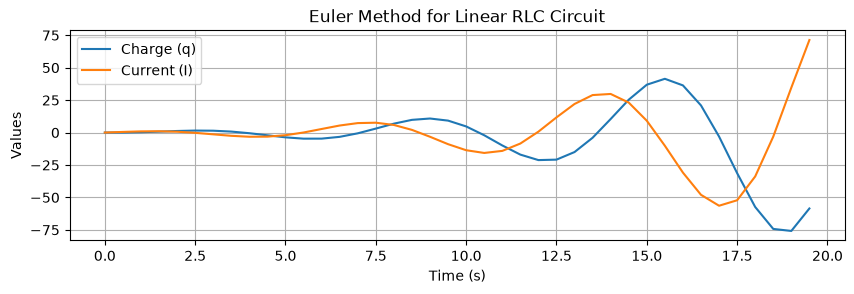

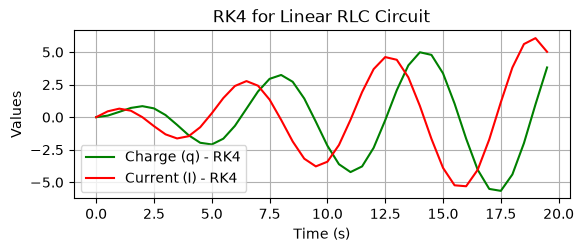

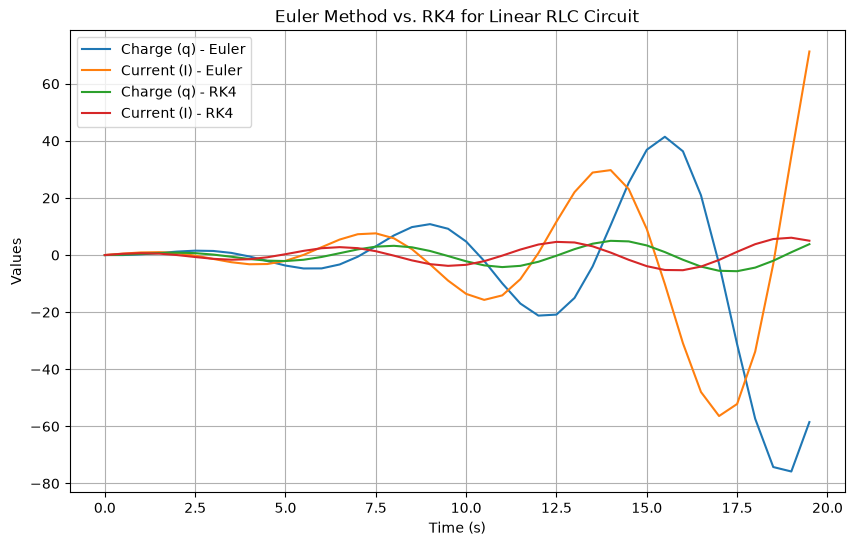

In [8]:
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.plot(time, q_Euler, label='Charge (q)')
plt.plot(time, I_Euler, label='Current (I)')
plt.xlabel('Time (s)')
plt.ylabel('Values')
plt.title('Euler Method for Linear RLC Circuit')
plt.legend()
plt.grid()
plt.show()
    
plt.subplot(2, 1, 2)    
plt.plot(time, q_RK4, label='Charge (q) - RK4', color='green')
plt.plot(time, I_RK4, label='Current (I) - RK4', color='red')
plt.xlabel('Time (s)')
plt.ylabel('Values')
plt.title('RK4 for Linear RLC Circuit')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(time, q_Euler, label='Charge (q) - Euler')
plt.plot(time, I_Euler, label='Current (I) - Euler')
plt.plot(time, q_RK4, label='Charge (q) - RK4')
plt.plot(time, I_RK4, label='Current (I) - RK4')
plt.xlabel('Time (s)')
plt.ylabel('Values')
plt.title('Euler Method vs. RK4 for Linear RLC Circuit')
plt.legend()
plt.grid()
plt.show()



The Euler vs RK4 plot show us how the Euler lines drift away from the stable RK4 lines.